<a href="https://colab.research.google.com/github/NikhilTheAi/NikhilTheAi-Machine-Learning-Experiments/blob/main/SentimentAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPERIMENT 6 - Sentiment Analysis

## Step 1 - Import Required Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## Step 2 - Load the Dataset

In [2]:
df = pd.read_csv("restaurant_reviews_1000.csv")

## Step 3 - Display the Dataset

In [3]:
df.head()

,review,sentiment,label
0,I really enjoyed this restaurant; the salad ta...,positive,1
1,I would gladly return because the sandwich was...,positive,1
2,"The meal was pleasant, fresh, and reasonably p...",positive,1
3,I would gladly return because the curry was ou...,positive,1
4,I will not return because the salad was bland ...,negative,0


## Step 4 - Check Dataset Information

In [4]:
print("Shape of Dataset:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Shape of Dataset: (1000, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     1000 non-null   object
 1   sentiment  1000 non-null   object
 2   label      1000 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 23.6+ KB

Missing Values:
review       0
sentiment    0
label        0
dtype: int64


## Step 5 - Check Sentiment Distribution

sentiment
positive    500
negative    500
Name: count, dtype: int64


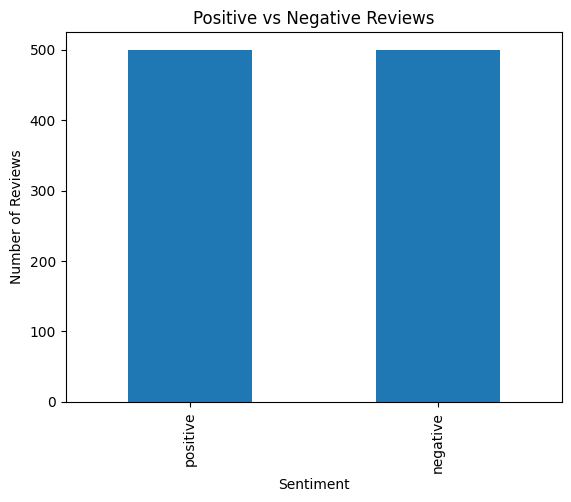

In [5]:
print(df["sentiment"].value_counts())

df["sentiment"].value_counts().plot(kind="bar")

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

## Step 6 - Separate Input and Output

In [6]:
X = df["review"]
y = df["label"]

print(X.head())
print(y.head())

0    I really enjoyed this restaurant; the salad ta...
1    I would gladly return because the sandwich was...
2    The meal was pleasant, fresh, and reasonably p...
3    I would gladly return because the curry was ou...
4    I will not return because the salad was bland ...
Name: review, dtype: object
0    1
1    1
2    1
3    1
4    0
Name: label, dtype: int64


## Step 7 - Split Dataset into Training and Testing Data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (800,)
Testing Data: (200,)


## Step 8 - Convert Text into Numerical Features Using TF-IDF

In [8]:
tfidf = TfidfVectorizer(
    stop_words="english",
    lowercase=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (800, 70)
Testing TF-IDF Shape: (200, 70)


## Step 9 - Naive Bayes

In [9]:
nb = MultinomialNB()

nb.fit(X_train_tfidf, y_train)

nb_pred = nb.predict(X_test_tfidf)

nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("Accuracy:", nb_accuracy)
print("Precision:", nb_precision)
print("Recall:", nb_recall)
print("F1-Score:", nb_f1)

print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



## Step 10 - Logistic Regression

In [10]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_tfidf, y_train)

lr_pred = lr.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-Score:", lr_f1)

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



## Step 11 - Support Vector Machine (SVM)

In [11]:
svm = SVC(kernel="linear")

svm.fit(X_train_tfidf, y_train)

svm_pred = svm.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1-Score:", svm_f1)

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



## Step 12 - Random Forest

In [12]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_tfidf, y_train)

rf_pred = rf.predict(X_test_tfidf)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-Score:", rf_f1)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



## Step 13 - Comparative Analysis of All Algorithms

In [13]:
results = pd.DataFrame({
    "Algorithm": [
        "Naive Bayes",
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],

    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy,
        rf_accuracy
    ],

    "Precision": [
        nb_precision,
        lr_precision,
        svm_precision,
        rf_precision
    ],

    "Recall": [
        nb_recall,
        lr_recall,
        svm_recall,
        rf_recall
    ],

    "F1-Score": [
        nb_f1,
        lr_f1,
        svm_f1,
        rf_f1
    ]
})

results

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0


## Step 14 - Plot Comparative Analysis

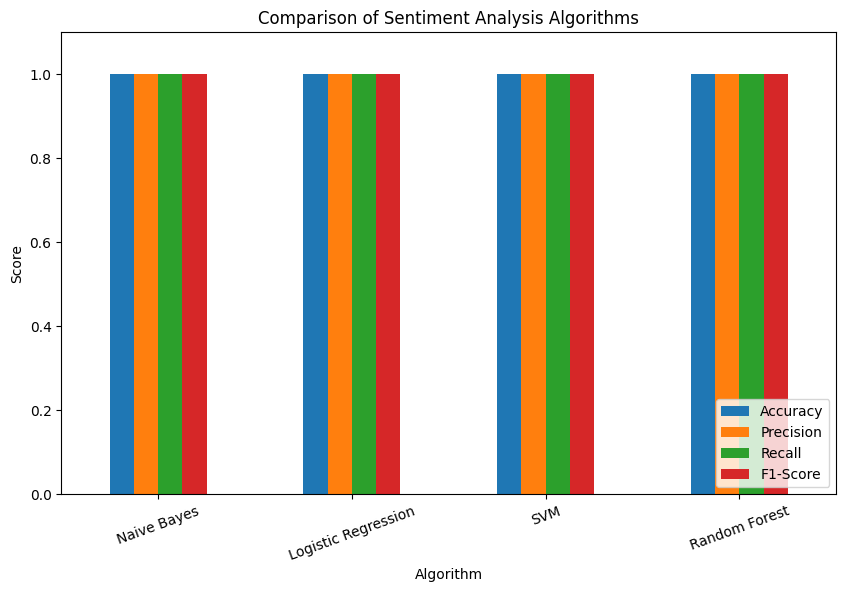

In [14]:
results.set_index("Algorithm").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Sentiment Analysis Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

## Step 15 - Find the Best Performing Algorithm

In [15]:
best_model = results.loc[results["F1-Score"].idxmax()]

print("Best Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

Best Algorithm: Naive Bayes
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


## Step 16 - Confusion Matrix

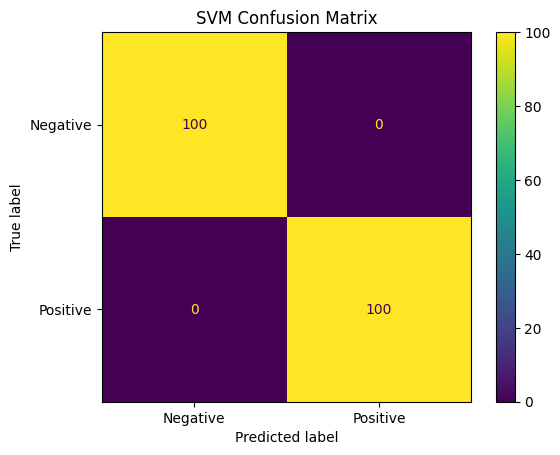

In [16]:
cm = confusion_matrix(y_test, svm_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot()

plt.title("SVM Confusion Matrix")
plt.show()

## Step 17 - Test the Model with New Reviews

In [17]:
review = ["The food was delicious and the service was excellent."]

review_tfidf = tfidf.transform(review)

prediction = svm.predict(review_tfidf)

if prediction[0] == 1:
    print("Positive Review")
else:
    print("Negative Review")

Positive Review


In [18]:
review = ["The food was terrible and the service was very bad."]

review_tfidf = tfidf.transform(review)

prediction = svm.predict(review_tfidf)

if prediction[0] == 1:
    print("Positive Review")
else:
    print("Negative Review")

Negative Review


## Conclusion

- Successfully performed sentiment analysis on restaurant reviews.
- Used TF-IDF for converting text into numerical features.
- Compared Naive Bayes, Logistic Regression, SVM, and Random Forest.
- Models were evaluated using Accuracy, Precision, Recall, and F1-Score.
- The best-performing model was identified for classifying reviews as Positive or Negative.